# Gaussian Mixture Model
**Purpose:** Test a probabilistic clustering method that allows overlapping, elliptical groups.

**Input:** `data/features/delhi_scaled.csv` (wind direction excluded), `delhi_features.csv`, `delhi_context.csv`, `data/results/kmeans_labels.csv`

**Outputs:** `data/results/gmm_labels.csv`, `data/results/gmm_probabilities.csv`, `models/gmm_k5_noSO2.pkl`

## 1. Load features and KMeans labels

In [2]:
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score
import joblib

BASE = Path.cwd().parent
X = pd.read_csv(BASE / "data" / "features" / "delhi_scaled.csv", parse_dates=["Date"], index_col="Date")
Xn = X.drop(columns=["wind_dir_sin", "wind_dir_cos"])
feat = pd.read_csv(BASE / "data" / "features" / "delhi_features.csv", parse_dates=["Date"], index_col="Date")
ctx = pd.read_csv(BASE / "data" / "features" / "delhi_context.csv", parse_dates=["Date"], index_col="Date")
km = pd.read_csv(BASE / "data" / "results" / "kmeans_labels.csv", parse_dates=["Date"], index_col="Date")["kmeans_cluster"]
print(Xn.shape)      

(1195, 13)


## 2. BIC, AIC and silhouette for 2-10 components
Full covariance fits far better than diagonal (BIC about 15,000 vs 25,000+), because the pollutants are strongly correlated.

In [3]:
rows = []
for cov in ["full", "diag"]:
    for k in range(2, 11):
        gm = GaussianMixture(n_components=k, covariance_type=cov, n_init=5, random_state=42).fit(Xn)
        lab = gm.predict(Xn)
        rows.append({"cov": cov, "k": k, "BIC": gm.bic(Xn), "AIC": gm.aic(Xn),
                     "silhouette": silhouette_score(Xn, lab)})
res = pd.DataFrame(rows)
print(res.round(1).to_string(index=False))

 cov  k     BIC     AIC  silhouette
full  2 17782.8 16719.9         0.1
full  3 16920.8 15323.8         0.1
full  4 16579.6 14448.7         0.1
full  5 16746.4 14081.4         0.1
full  6 14936.9 11737.9         0.1
full  7 14947.2 11214.2         0.1
full  8 14907.9 10640.8         0.1
full  9 14530.6  9729.5         0.0
full 10 15196.1  9861.0         0.0
diag  2 31941.2 31671.7         0.2
diag  3 29490.0 29083.1         0.1
diag  4 26757.4 26213.2         0.1
diag  5 26509.3 25827.7         0.1
diag  6 24933.0 24114.1         0.1
diag  7 24640.9 23684.8         0.1
diag  8 24415.2 23321.7         0.1
diag  9 24248.2 23017.4         0.1
diag 10 23875.2 22507.0         0.1


## 3. Plot BIC and silhouette
BIC flattens after k=6, but BIC assumes independent days and tends to favour too many components for time series.

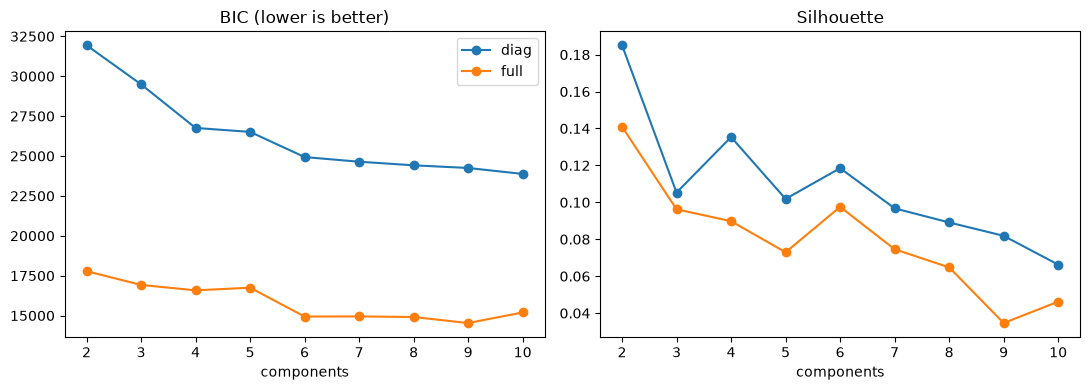

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for cov, g in res.groupby("cov"):
    axes[0].plot(g["k"], g["BIC"], marker="o", label=cov)
    axes[1].plot(g["k"], g["silhouette"], marker="o", label=cov)
axes[0].set_title("BIC (lower is better)"); axes[1].set_title("Silhouette")
for a in axes: a.set_xlabel("components")
axes[0].legend(); plt.tight_layout(); plt.show()

## 4. Stability across random starts
Full covariance: k=5 is very stable (0.99), k=6 is not (0.58).

In [5]:
def gm_stability(data, k, cov, n=8):
    base = GaussianMixture(n_components=k, covariance_type=cov, n_init=1, random_state=0).fit(data).predict(data)
    return np.mean([adjusted_rand_score(base, GaussianMixture(n_components=k, covariance_type=cov, n_init=1, random_state=s).fit(data).predict(data))
                    for s in range(1, n + 1)])

for k in range(2, 9):
    print(k, "full:", round(gm_stability(Xn, k, "full"), 3), " diag:", round(gm_stability(Xn, k, "diag"), 3))

2 full: 1.0  diag: 0.983
3 full: 0.499  diag: 0.842
4 full: 0.968  diag: 0.874
5 full: 0.992  diag: 1.0
6 full: 0.579  diag: 0.596
7 full: 0.593  diag: 0.647
8 full: 0.664  diag: 0.602


## 5. Profile k = 4, 5, 6
Raw averages, month and year distributions, and agreement with KMeans (ARI 0.15 to 0.27).

In [6]:
raw = feat.drop(columns=["wind_dir_sin", "wind_dir_cos"])
models = {}
for k in [4, 5, 6]:
    gm = GaussianMixture(n_components=k, covariance_type="full", n_init=20, random_state=42).fit(Xn)
    models[k] = gm
    lab = pd.Series(gm.predict(Xn), index=Xn.index, name="gmm")
    conf = pd.Series(gm.predict_proba(Xn).max(axis=1), index=Xn.index)

    prof = raw.groupby(lab).mean().round(1)
    prof["days"] = lab.value_counts().sort_index()
    prof["AQI"] = ctx["AQI"].groupby(lab).mean().round(0)

    print(f"\n===== GMM full, k = {k} =====")
    print(prof.T)
    print(pd.crosstab(lab, ctx["month"]))
    print(pd.crosstab(lab, ctx["year"]))                     # era check
    print("ARI vs KMeans k=5:", round(adjusted_rand_score(km, lab), 3))
    print(pd.crosstab(lab, km))                              # rows = GMM, columns = KMeans
    print("mean max-probability:", round(conf.mean(), 2),
          "| days with max-prob < 0.7:", int((conf < 0.7).sum()))


===== GMM full, k = 4 =====
gmm             0      1      2      3
PM2.5        87.0  142.2  145.1   38.5
PM10        268.8  267.7  221.0   93.1
NO           28.7   47.5   40.3   14.2
NO2          44.2   54.1   50.3   28.2
NH3          38.7   43.6   41.6   32.3
SO2          17.4   17.6   16.3   10.1
O3           46.3   44.6   35.4   32.4
CO            1.0    1.4    1.2    0.9
Benzene       2.6    4.1    4.0    1.9
PM_ratio      0.3    0.5    0.6    0.4
temp         29.6   22.4   16.7   28.7
rain          1.2    0.0    3.4    5.8
wind_speed   20.5   14.6   15.7   15.1
days        123.0  770.0  103.0  199.0
AQI         249.0  286.0  292.0  109.0
month  1   2   3   4   5   6   7   8   9   10  11   12
gmm                                                   
0       0   5  13  30  30  28   5   6   2   4   0    0
1      87  82  89  80  84  51   7   1  15  83  77  114
2      36  23  18   1   1   0   0   0   0   1  13   10
3       0   0   4   9   9  18  51  55  48   5   0    0
year  2016  2017 

## 7. Re-fit without SO2
The 2017 components disappear. At k=5 the sizes are balanced (114/122/379/186/394), stability is 0.66.

In [7]:
Xs = Xn.drop(columns=["SO2"])
for k in [4, 5, 6]:
    gm = GaussianMixture(n_components=k, covariance_type="full", n_init=20, random_state=42).fit(Xs)
    lab = pd.Series(gm.predict(Xs), index=Xs.index)
    yr = pd.crosstab(lab, ctx["year"])

    print(f"\n=== GMM without SO2, k={k} ===")
    print("sizes:", lab.value_counts().sort_index().tolist())
    print("largest single-year share:", (yr.max(axis=1) / yr.sum(axis=1)).round(2).tolist())
    print("stability:", round(gm_stability(Xs, k, "full"), 3))
    print("ARI vs KMeans k=5:", round(adjusted_rand_score(km, lab), 3))

    prof = raw.drop(columns=["SO2"]).groupby(lab).mean().round(1)
    prof["days"] = lab.value_counts().sort_index()
    prof["AQI"] = ctx["AQI"].groupby(lab).mean().round(0)
    print(prof.T)
    print(pd.crosstab(lab, km))        # rows = GMM, columns = KMeans


=== GMM without SO2, k=4 ===
sizes: [109, 741, 225, 120]
largest single-year share: [0.5, 0.3, 0.44, 0.42]
stability: 0.975
ARI vs KMeans k=5: 0.139
                0      1      2      3
PM2.5       151.7  143.1   47.0   80.3
PM10        223.9  270.4  108.0  262.1
NO           42.0   47.5   16.5   30.2
NO2          48.3   54.5   31.5   42.9
NH3          43.8   43.4   33.6   38.2
O3           35.1   45.1   34.5   42.6
CO            1.1    1.4    1.0    0.9
Benzene       3.4    4.3    2.2    2.3
PM_ratio      0.7    0.5    0.4    0.3
temp         19.0   22.2   27.3   30.6
rain          2.4    0.0    5.5    1.3
wind_speed   14.7   14.7   15.3   20.5
days        109.0  741.0  225.0  120.0
AQI         301.0  288.0  124.0  239.0
kmeans_cluster    0    1    2    3    4
row_0                                  
0                 8   65    3   19   14
1                 0  217  157  210  157
2               149   15    9    1   51
3                18    2   50    1   49

=== GMM without SO2, k=5

## 8. Final model: k=5, full covariance, SO2 excluded
Components: dust-like, cold winter with rain, cold calm smog, monsoon washout, mixed moderate. Labels and probabilities saved.

In [8]:
Xs = Xn.drop(columns=["SO2"])
gm = GaussianMixture(n_components=5, covariance_type="full", n_init=20, random_state=42).fit(Xs)
proba = gm.predict_proba(Xs)
labels = pd.Series(gm.predict(Xs), index=Xs.index, name="gmm_cluster")

# numbering check: component 3 should have the most rain, component 0 the highest wind
print(raw.drop(columns=["SO2"]).groupby(labels)[["rain", "PM2.5", "temp", "wind_speed"]].mean().round(1))
print("mean max probability:", round(proba.max(axis=1).mean(), 3))
print("days below 0.7:", int((proba.max(axis=1) < 0.7).sum()))

# save
(BASE / "data" / "results").mkdir(parents=True, exist_ok=True)
labels.to_csv(BASE / "data" / "results" / "gmm_labels.csv")
pd.DataFrame(proba, index=Xs.index, columns=[f"p{i}" for i in range(5)]).to_csv(BASE / "data" / "results" / "gmm_probabilities.csv")
joblib.dump(gm, BASE / "models" / "gmm_k5_noSO2.pkl")
print("saved")

             rain  PM2.5  temp  wind_speed
gmm_cluster                               
0             1.5   79.2  30.4        20.7
1             3.0  149.9  17.5        15.6
2             0.0  189.1  17.7        13.0
3             6.0   39.7  28.7        15.0
4             0.0   92.5  27.1        16.3
mean max probability: 0.987
days below 0.7: 14
saved


## Conclusion
GMM does not outperform KMeans on this data. It agrees on the monsoon washout (82% overlap) and finds a hot, windy, coarse-particle group, plus a cold winter group with some rain that KMeans does not isolate.
It merges severe and moderate winter smog at k=5; k=6 separates them but is unstable.
BIC kept falling partly because an extra component fitted the 2017 SO2 anomaly; removing SO2 removed that component.
Membership probabilities are close to 0 or 1 (mean max probability about 0.98), so GMM behaved like hard clustering here.